# 03 - Price sensitivity (price elasticity)

**Question:** if we raise our price by 1%, by how much does demand fall?

That number is the **own-price elasticity**. We estimate it with a log-log regression, where the coefficient on
log(price) is the elasticity. The data is a **panel** (6 regions x 48 months), so we compare each region with
itself and remove other effects (season, promotions, competitor, economy) that also move demand.

**Input:** `data/panel_clean.csv` from notebook 01.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

df = pd.read_csv("data/panel_clean.csv", parse_dates=["date"])
df = df.sort_values(["region", "date"]).reset_index(drop=True)   # needed for the standard errors below

df["log_demand"] = np.log(df["demand_tons"])
df["log_price"] = np.log(df["price_usd_per_ton"])
df["log_comp_price"] = np.log(df["competitor_price_usd_per_ton"])
df["log_index"] = np.log(df["industrial_index"])
df["month"] = df["date"].dt.month
df["year"] = df["date"].dt.year
regions = sorted(df["region"].unique())

In [2]:
def fit(formula, data):
    """OLS with HAC-panel standard errors: allows a region's months to be correlated with each other,
    so the confidence intervals are not too optimistic."""
    groups = pd.Categorical(data["region"]).codes
    return smf.ols(formula, data=data).fit(cov_type="hac-panel", cov_kwds={"groups": groups, "maxlags": 3})


def elasticity(model, name="log_price"):
    low, high = model.conf_int().loc[name]
    return model.params[name], low, high

## 2. Build the estimate step by step

We start with the simplest model and add one control at a time. Watching the number move shows which
effects were hiding inside the simple answer.

In [3]:
steps = {
    "1. Price only (all regions pooled)":     "log_demand ~ log_price",
    "2. + region effects":                    "log_demand ~ log_price + C(region)",
    "3. + month effects (seasonality)":       "log_demand ~ log_price + C(region) + C(month)",
    "4. + promotion, competitor price":       "log_demand ~ log_price + C(region) + C(month) + promo_flag + log_comp_price",
    "5. + industrial index (FINAL)":          "log_demand ~ log_price + C(region) + C(month) + promo_flag + log_comp_price + log_index",
}

rows = []
for name, formula in steps.items():
    e, low, high = elasticity(fit(formula, df))
    rows.append({"Model": name, "Elasticity": e, "95% CI low": low, "95% CI high": high})

build_up = pd.DataFrame(rows)
build_up.round(2)

,Model,Elasticity,95% CI low,95% CI high
0,1. Price only (all regions pooled),-3.040,-3.590,-2.500
1,2. + region effects,-2.190,-2.490,-1.890
2,3. + month effects (seasonality),-2.240,-2.400,-2.070
3,"4. + promotion, competitor price",-2.300,-2.430,-2.180
4,5. + industrial index (FINAL),-2.060,-2.160,-1.970


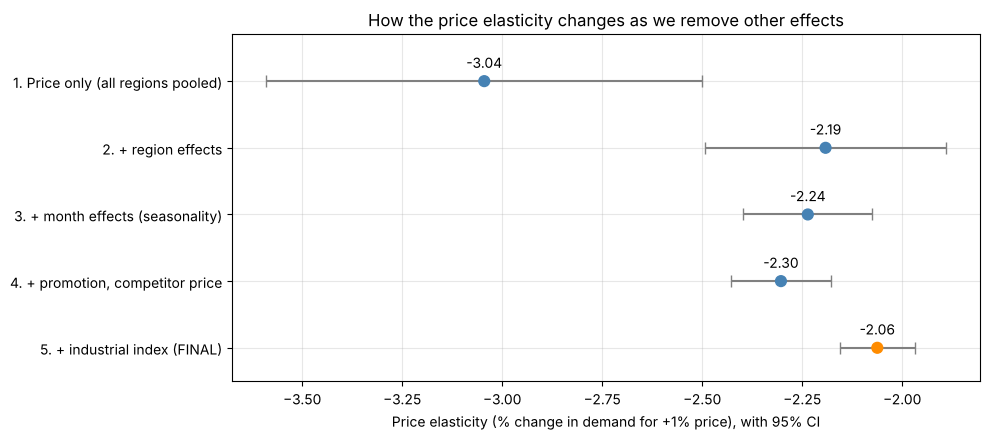

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
y = range(len(build_up))[::-1]
colors = ["darkorange" if "FINAL" in m else "steelblue" for m in build_up["Model"]]

ax.errorbar(build_up["Elasticity"], y,
            xerr=[build_up["Elasticity"] - build_up["95% CI low"], build_up["95% CI high"] - build_up["Elasticity"]],
            fmt="none", ecolor="grey", capsize=4)
ax.scatter(build_up["Elasticity"], y, color=colors, s=60, zorder=3)
for yi, value in zip(y, build_up["Elasticity"]):
    ax.text(value, yi + 0.2, f"{value:.2f}", ha="center")

ax.set_yticks(list(y))
ax.set_yticklabels(build_up["Model"])
ax.set_ylim(-0.5, len(build_up) - 0.3)
ax.set_xlabel("Price elasticity (% change in demand for +1% price), with 95% CI")
ax.set_title("How the price elasticity changes as we remove other effects")
plt.tight_layout()
plt.show()

**What we see**
- **Price only, all regions pooled: -3.04.** This is misleading. Cheap regions (Gulf Coast, Southeast, West) are also the big ones, so the model mistakes "big region" for "low price works wonders".
- **+ region effects: -2.19.** Each region is now compared with itself. This is the biggest correction, and it is why the panel structure matters.
- **+ season, promotions, competitor:** small moves (-2.24, then -2.30), with a much narrower confidence interval.
- **+ industrial index: -2.06 (final).** Our prices fell while the economy grew, so without the index part of the economy-driven growth was wrongly credited to price cuts.

**So what:** the honest answer is about **-2.1**, not -3. Ignoring the panel structure and the economy would overstate price sensitivity by roughly 50%.

In [5]:
final = fit(steps["5. + industrial index (FINAL)"], df)

drivers = ["log_price", "promo_flag", "log_comp_price", "log_index"]
pd.DataFrame({
    "coefficient": final.params[drivers],
    "95% CI low": final.conf_int().loc[drivers, 0],
    "95% CI high": final.conf_int().loc[drivers, 1],
    "p-value": final.pvalues[drivers],
}).round(3)

,coefficient,95% CI low,95% CI high,p-value
log_price,-2.062,-2.156,-1.969,0.000
promo_flag,0.079,0.064,0.093,0.000
log_comp_price,0.484,0.373,0.594,0.000
log_index,1.508,1.242,1.774,0.000


**What we see:** in the final model every driver is clearly significant (p < 0.001):
- **Our price -2.06** (95% CI -2.16 to -1.97): +1% price -> about **-2.1% demand**.
- **Promotion +0.08:** about **+8%** demand in promotion months.
- **Competitor price +0.48:** if the competitor raises price 1%, our demand rises about **0.5%**.
- **Industrial index +1.51:** 1% more industrial activity -> about **1.5%** more demand.

## 3. Is price sensitivity different by region?

Same final model, but with a separate price effect for each region (a `region x log_price` interaction).
Then a **Wald test**: are all six elasticities equal?

In [6]:
by_region_model = fit("log_demand ~ C(region):log_price + C(region) + C(month) + promo_flag + log_comp_price + log_index", df)

rows = []
for r in regions:
    e, low, high = elasticity(by_region_model, f"C(region)[{r}]:log_price")
    price_variation = df.loc[df["region"] == r, "price_usd_per_ton"].std() / df.loc[df["region"] == r, "price_usd_per_ton"].mean() * 100
    rows.append({"Region": r, "Elasticity": e, "95% CI low": low, "95% CI high": high,
                 "Price variation (%)": price_variation})
by_region = pd.DataFrame(rows)

names = [f"C(region)[{r}]:log_price" for r in regions]
test = by_region_model.wald_test(" = ".join(names))
print(f"Wald test, all six elasticities equal: p-value = {float(np.squeeze(test.pvalue)):.2f}")
by_region.round(2)

Wald test, all six elasticities equal: p-value = 0.73


,Region,Elasticity,95% CI low,95% CI high,Price variation (%)
0,Great Lakes,-2.090,-2.330,-1.860,4.990
1,Gulf Coast,-1.860,-2.170,-1.560,4.650
2,Midwest,-2.060,-2.230,-1.890,7.270
3,Northeast,-2.030,-2.190,-1.880,8.820
4,Southeast,-1.980,-2.390,-1.570,3.440
5,West,-2.160,-2.350,-1.970,7.900


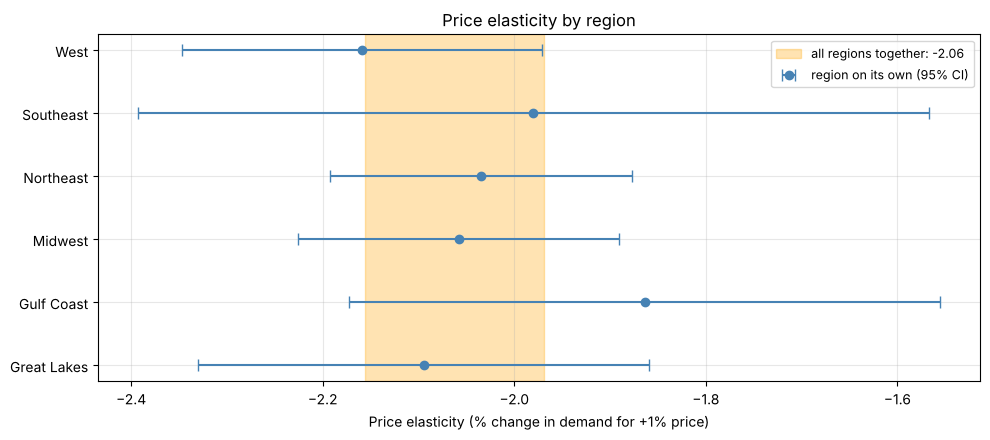

In [7]:
e_final, low_final, high_final = elasticity(final)

fig, ax = plt.subplots(figsize=(10, 4.5))
y = range(len(by_region))
ax.axvspan(low_final, high_final, color="orange", alpha=0.3, label=f"all regions together: {e_final:.2f}")
ax.errorbar(by_region["Elasticity"], y,
            xerr=[by_region["Elasticity"] - by_region["95% CI low"], by_region["95% CI high"] - by_region["Elasticity"]],
            fmt="o", color="steelblue", capsize=4, label="region on its own (95% CI)")
ax.set_yticks(list(y))
ax.set_yticklabels(by_region["Region"])
ax.set_xlabel("Price elasticity (% change in demand for +1% price)")
ax.set_title("Price elasticity by region")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

**What we see**
- The region elasticities range from -1.86 (Gulf Coast) to -2.16 (West), and all their confidence intervals overlap the pooled estimate.
- The Wald test gives **p = 0.73**, so there is no evidence that regions differ.
- Gulf Coast and Southeast have the widest intervals because their prices barely moved (about 4.7% and 3.4% variation). Little price movement means little to learn from.

**Decision:** use **one shared elasticity (-2.06)** for all regions. It is far more precise, and the data cannot support different values per region.

## 4. Robustness: does the answer hold on different slices of the data?

If the elasticity is real, it should not change much when we drop parts of the data.

In [8]:
final_formula = steps["5. + industrial index (FINAL)"]
no_promo_formula = final_formula.replace(" + promo_flag", "")

checks = {
    "All data (final model)":           (final_formula, df),
    "Months without promotion only":    (no_promo_formula, df[df["promo_flag"] == 0]),
    "2023-2024 only":                   (final_formula, df[df["year"] >= 2023]),
    "Months below plant capacity only": (final_formula, df[df["demand_tons"] <= df["monthly_capacity_tons"]]),
}

rows = []
for name, (formula, data) in checks.items():
    e, low, high = elasticity(fit(formula, data))
    rows.append({"Check": name, "Rows": len(data), "Elasticity": e, "95% CI low": low, "95% CI high": high})
pd.DataFrame(rows).round(2)

,Check,Rows,Elasticity,95% CI low,95% CI high
0,All data (final model),288,-2.060,-2.160,-1.970
1,Months without promotion only,229,-2.070,-2.180,-1.970
2,2023-2024 only,144,-2.040,-2.200,-1.880
3,Months below plant capacity only,242,-2.010,-2.120,-1.890


**What we see:** the elasticity stays between **-2.01 and -2.07** in every slice: without promotion months, using only 2023-2024, and only months where demand was below capacity. The confidence intervals all overlap.

**So what:** the estimate is not driven by promotions, by older data, or by months where capacity capped sales. It is stable.

**Limitation (endogeneity):** if prices were set *because* the team expected high or low demand, part of the price
effect could be reverse cause-and-effect. Removing season, promotions, competitor and economy reduces this risk
but cannot rule it out without cost data (an instrument). A controlled price test in one or two regions would
confirm the number.

## 5. What it means for the business

**Revenue vs margin.** With elasticity about -2, a 1% price rise loses about 2% of volume, so **revenue falls**.
But each ton we still sell earns more above the **$600/ton variable cost**, so **margin can still rise**.

**Best price (ignoring capacity).** With constant elasticity *e*, margin is highest at

price = cost x e / (1 + e)

which is the same as: margin = 1/|e| of the price.

In [9]:
VARIABLE_COST = 600

best_price = VARIABLE_COST * e_final / (1 + e_final)
best_low = VARIABLE_COST * low_final / (1 + low_final)
best_high = VARIABLE_COST * high_final / (1 + high_final)

print(f"Elasticity: {e_final:.2f}  (95% CI {low_final:.2f} to {high_final:.2f})")
print(f"Best price, ignoring capacity: ${best_price:,.0f}/t  (range ${best_low:,.0f} - ${best_high:,.0f})")
print(f"At that price, margin = {1 / abs(e_final):.0%} of price")

Elasticity: -2.06  (95% CI -2.16 to -1.97)
Best price, ignoring capacity: $1,165/t  (range $1,119 - $1,219)
At that price, margin = 48% of price


In [10]:
# what would a +5% price rise do, region by region, at 2024 prices? (capacity is added in notebook 04)
price_2024 = df[df["year"] == 2024].groupby("region")["price_usd_per_ton"].mean()

impact = pd.DataFrame({"Price 2024 ($/t)": price_2024})
impact["Margin today (% of price)"] = (price_2024 - VARIABLE_COST) / price_2024 * 100
impact["Volume change (%)"] = (1.05 ** e_final - 1) * 100
impact["Revenue change (%)"] = (1.05 * 1.05 ** e_final - 1) * 100
impact["Margin change (%)"] = ((price_2024 * 1.05 - VARIABLE_COST) * 1.05 ** e_final
                               / (price_2024 - VARIABLE_COST) - 1) * 100
impact.round(1)

,Price 2024 ($/t),Margin today (% of price),Volume change (%),Revenue change (%),Margin change (%)
region,,,,,
Great Lakes,"1,143.900",47.500,-9.600,-5.100,-0.100
Gulf Coast,"1,003.800",40.200,-9.600,-5.100,1.700
Midwest,"1,034.200",42.000,-9.600,-5.100,1.200
Northeast,982.100,38.900,-9.600,-5.100,2.000
Southeast,960.200,37.500,-9.600,-5.100,2.500
West,953.300,37.100,-9.600,-5.100,2.600


**What we see**
- The margin-maximising price is about **$1,165/t** (range $1,119-1,219). At that price, margin is about **48%** of price.
- In 2024 most regions priced well below that: West $953 (margin 37%), Southeast $960 (38%), Northeast $982 (39%). Great Lakes ($1,144, 48%) is already about at the best price.
- A **+5% price rise** cuts volume by about 9.6% and revenue by about 5.1%, but **raises margin by 1-2.6%** in five regions. Great Lakes stays flat (-0.1%) because it is already at the optimum.

**Caveat:** this ignores capacity. Where demand already exceeds capacity, the volume we lose was partly unsellable anyway, so the real gain is bigger. Notebook 04 adds capacity.

## 6. Summary

| Question | Answer |
|---|---|
| Price elasticity | **-2.06** (95% CI -2.16 to -1.97): +1% price -> about -2.1% demand |
| Why not the simple -3.04? | Pooling mixes region size with price; the economy grew while prices fell |
| Different by region? | No (Wald p = 0.73) -> one shared value |
| Stable? | Yes: -2.01 to -2.07 across slices |
| Other drivers | Promotion +8%, competitor price +0.48, economy +1.51 |
| Best price (no capacity limit) | about **$1,165/t** (margin 48% of price) |
| 2024 position | Most regions price below that -> room to raise prices |
| Limitation | Cannot fully rule out prices set in reaction to demand -> confirm with a price test |

**Next:** notebook 04 - pricing recommendation per region, including the capacity limits.